# 02 · Voting network analysis of the Faroese Parliament (Løgtingið), 2020–2023

**DTU 02805 – Social Graphs and Interactions · network-analysis workstream**

## 1. Research question

The overall project asks:

> *To what extent do Faroese MPs who vote similarly also use similar language when discussing the same parliamentary cases?*

This notebook covers the **voting side**. It builds (A) an MP–division bipartite network and (B) a weighted MP–MP voting-similarity network, checks them against null models, and exports pairwise tables in a format the speech-similarity workstream can join directly (`mp_id_1, mp_id_2, similarity, n_shared_divisions`).

**What this notebook does *not* do:** it does not analyse speeches, and it does not define the final dissent measure (that is another workstream). Where a dissent table is exported it is explicitly *exploratory*.

**Conventions used throughout**

| Vote label | Meaning | Treatment |
|---|---|---|
| `Fyri` | For | valid vote |
| `Ímóti` | Against | valid vote |
| `Blankt` | Blank | *not* used in the main agreement measure (tested as a sensitivity check) |
| empty | absent | never a vote, never dissent |

All paths are relative to the repository root, all randomness uses the fixed seed `SEED`, and nothing in this notebook writes outside `network_analysis/outputs/`.

In [1]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display, Markdown

# locate the repository root (works wherever the notebook is launched from)
ROOT = Path.cwd().resolve()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "network_analysis" / "src" / "networks.py").exists():
        ROOT = cand
        break
sys.path.insert(0, str(ROOT / "network_analysis" / "src"))
import networks as N

SEED = 2805                      # one seed, used to derive every random generator below
MIN_OVERLAPS = (20, 40, 60)      # sensitivity thresholds; 40 is the main analysis
MAIN_OVERLAP = 40
R = {"parameters": {"seed": SEED, "min_overlaps": list(MIN_OVERLAPS), "main_min_overlap": MAIN_OVERLAP,
                    "window_start": str(N.WINDOW_START.date()), "window_end": str(N.WINDOW_END.date())}}

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
                     "legend.frameon": False, "savefig.facecolor": "white"})
INK, MUTED = "#1c1c1b", "#6b6a66"
C_FOR, C_AGAINST, C_BLANK, C_ABSENT = "#2a78d6", "#eb6834", "#b8b8b4", "#f4f4f2"

def save_fig(fig, name):
    """Save PNG (300 dpi) and PDF into network_analysis/outputs/figures/."""
    for ext in ("png", "pdf"):
        fig.savefig(N.output_path(ROOT, "figures", f"{name}.{ext}"), dpi=300, bbox_inches="tight")

def save_table(df, name, index=False):
    df.to_csv(N.output_path(ROOT, "tables", name), index=index)

print("repository root:", ROOT)
print("pandas", pd.__version__, "| networkx", nx.__version__, "| numpy", np.__version__)

repository root: <repository root>
pandas 3.1.1 | networkx 3.7 | numpy 2.5.4


## 2. Load and inspect the data

The four source tables are read from `data/*_2020-2023.parquet` (the CSV copies were verified to be identical to the Parquet files). They are read-only here: nothing is modified or copied.

In [2]:
data = N.load_data(ROOT)
ballots, votes, cases, members = (data[k] for k in ("ballots", "votes", "cases", "members"))

display(pd.DataFrame({k: {"rows": len(v), "columns": v.shape[1]} for k, v in data.items()}).T)
for k, v in data.items():
    print(f"{k}: {list(v.columns)}")
display(ballots.head(3))

,rows,columns
ballots,31085,7
votes,1125,17
cases,514,9
members,68,5


ballots: ['vote_id', 'case_id', 'mp_id', 'actor_id', 'name', 'party', 'vote']
votes: ['vote_id', 'case_id', 'case_number', 'case_title', 'case_type', 'year', 'subject', 'vote_title', 'stage', 'meeting_id', 'meeting_date', 'protocol_name', 'result', 'n_for', 'n_middle', 'n_against', 'url']
cases: ['case_id', 'case_number', 'case_title', 'committee', 'status', 'case_type_id', 'case_type', 'year', 'url']
members: ['actor_id', 'mp_id', 'name', 'parties', 'n_ballots']


,vote_id,case_id,mp_id,actor_id,name,party,vote
0,7141,9637,MPID000010,10,Annika Olsen,Fólkaflokkurin,Fyri
1,7141,9637,MPID000001,1,Beinir Johannesen,Fólkaflokkurin,Fyri
2,7141,9637,MPID000011,11,Brandur Sandoy,Fólkaflokkurin,Fyri


In [3]:
# missing values per table (only columns that have any)
for k, v in data.items():
    s = v.isna().sum()
    print(f"{k:8s} missing:", s[s > 0].to_dict() or "none")
print("ballots with an empty vote label (= absent):", int((ballots.vote == "").sum()))

# integrity checks
cnt = ballots.groupby(["vote_id", "vote"]).size().unstack(fill_value=0)
tally = votes.set_index("vote_id").join(cnt, how="inner")
tally_mismatch = tally[(tally.n_for != tally[N.FOR]) | (tally.n_against != tally[N.AGAINST])
                       | (tally.n_middle != tally[N.BLANK])]
checks = {
    "duplicate (vote_id, mp_id) ballot rows": int(ballots.duplicated(["vote_id", "mp_id"]).sum()),
    "ballot vote_ids missing from votes": int((~ballots.vote_id.isin(votes.vote_id)).sum()),
    "votes.case_id missing from cases": int((~votes.case_id.isin(cases.case_id)).sum()),
    "ballot mp_ids missing from members": int((~ballots.mp_id.isin(members.mp_id)).sum()),
    "mp_id != 'MPID%06d' % actor_id": int((ballots.mp_id != ballots.actor_id.map("MPID{:06d}".format)).sum()),
    "votes without any ballot rows (tally only)": int((~votes.vote_id.isin(ballots.vote_id)).sum()),
    "votes without meeting_date": int(votes.meeting_date.isna().sum()),
    "votes whose stored tally != ballot counts": len(tally_mismatch),
}
display(pd.Series(checks, name="count").to_frame())
R["data_checks"] = checks

ballots  missing: none
votes    missing: {'meeting_id': 22, 'meeting_date': 7, 'protocol_name': 22, 'n_for': 9, 'n_middle': 9, 'n_against': 9}
cases    missing: none
members  missing: none
ballots with an empty vote label (= absent): 233


,count
"duplicate (vote_id, mp_id) ballot rows",0
ballot vote_ids missing from votes,0
votes.case_id missing from cases,0
ballot mp_ids missing from members,0
mp_id != 'MPID%06d' % actor_id,0
votes without any ballot rows (tally only),11
votes without meeting_date,7
votes whose stored tally != ballot counts,0


In [4]:
# vote labels, parties, MP identifiers
print("vote labels:", ballots.vote.value_counts().to_dict())
assert set(ballots.party) <= set(N.PARTY_ORDER), set(ballots.party) - set(N.PARTY_ORDER)
party_votes = pd.crosstab(ballots.party, ballots.vote.replace({"": "(absent)"})).reindex(N.PARTY_ORDER)
display(party_votes)

n_party = ballots.groupby("mp_id").party.nunique()
switchers = n_party[n_party > 1].index.tolist()
print("MPs:", ballots.mp_id.nunique(), "| MPs listed under more than one party:",
      [(m, members.set_index("mp_id").name[m], sorted(ballots[ballots.mp_id == m].party.unique())) for m in switchers])
R["data"] = {"n_ballots": len(ballots), "n_votes": len(votes), "n_cases": len(cases), "n_members": len(members),
             "party_switchers": switchers}

vote labels: {'Fyri': 23192, 'Ímóti': 7391, 'Blankt': 269, '': 233}


vote,(absent),Blankt,Fyri,Ímóti
party,,,,
Javnaðarflokkurin,40,108,5800,1491
Tjóðveldi,50,68,4506,1120
Sambandsflokkurin,46,8,4732,1781
Fólkaflokkurin,39,21,4749,1929
Framsókn,10,51,1806,473
Miðflokkurin,16,12,1402,539
Sjálvstýri,32,1,197,58


MPs: 68 | MPs listed under more than one party: [('MPID000010', 'Annika Olsen', ['Fólkaflokkurin', 'Tjóðveldi'])]


In [5]:
# relationships between votes, cases and meeting dates
per_case = votes.groupby("case_id").size()
print("divisions per case:", per_case.describe().round(2).to_dict())
print("divisions per meeting date:", votes.groupby("meeting_date").size().describe().round(2).to_dict())
print("meeting_date range:", votes.meeting_date.min().date(), "->", votes.meeting_date.max().date())
by_year = votes.groupby(["year", "case_type"]).size().unstack(fill_value=0)
by_year["total"] = by_year.sum(axis=1)
display(by_year)
print("note: `year` is the year of the CASE; the vote itself can be later (use meeting_date).")
print("share of votes held in a later calendar year than the case year:",
      round(float((votes.meeting_date.dt.year > votes.year).mean()), 3))

divisions per case: {'count': 459.0, 'mean': 2.45, 'std': 2.69, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 3.0, 'max': 38.0}
divisions per meeting date: {'count': 161.0, 'mean': 6.94, 'std': 7.01, 'min': 1.0, '25%': 2.0, '50%': 5.0, '75%': 9.0, 'max': 50.0}
meeting_date range: 2020-08-13 -> 2024-05-23


case_type,Fíggjarlógaruppskot,Lógaruppskot,Ríkislógartilmæli,Uppskot til Tingskipan,Uppskot til samtyktar,total
year,,,,,,
2020,57,239,20,0,37,353
2021,64,180,27,0,33,304
2022,20,117,17,6,17,177
2023,35,219,19,2,16,291


note: `year` is the year of the CASE; the vote itself can be later (use meeting_date).
share of votes held in a later calendar year than the case year: 0.609


### Restricting to the speech dataset's coverage

The speech transcripts (FPSC) cover **29 July 2020 – 4 May 2023**, so the main comparative analysis uses only divisions whose plenary meeting date falls in that window. The full dataset is kept for the descriptive tables above. Votes with no `meeting_date` cannot be placed in the window and drop out.

In [6]:
votes_w, ballots_w = N.restrict_window(votes, ballots)
outside = votes[~votes.vote_id.isin(votes_w.vote_id)]
print(f"divisions in window: {len(votes_w)} of {len(votes)}  "
      f"(after window end: {int((outside.meeting_date > N.WINDOW_END).sum())}, "
      f"before start: {int((outside.meeting_date < N.WINDOW_START).sum())}, undated: {int(outside.meeting_date.isna().sum())})")
print(f"divisions in window with a per-MP breakdown: {votes_w.vote_id.isin(ballots_w.vote_id).sum()}")
print(f"ballot rows in window: {len(ballots_w)} | MPs appearing: {ballots_w.mp_id.nunique()}")
R["window"] = {"divisions_total": len(votes), "divisions_in_window": len(votes_w),
               "divisions_in_window_with_ballots": int(votes_w.vote_id.isin(ballots_w.vote_id).sum()),
               "undated_excluded": int(outside.meeting_date.isna().sum()),
               "after_window_excluded": int((outside.meeting_date > N.WINDOW_END).sum()),
               "ballot_rows": len(ballots_w), "mps": int(ballots_w.mp_id.nunique())}

divisions in window: 743 of 1125  (after window end: 375, before start: 0, undated: 7)
divisions in window with a per-MP breakdown: 738
ballot rows in window: 20407 | MPs appearing: 66


## 3. Prepare the voting data

**Valid votes** are `Fyri` and `Ímóti` (blank is excluded from the main agreement measure; absence is never a vote).

**Contested division** (the rule used everywhere below): a division with **at least one For *and* at least one Against** among the MPs who voted. Unanimous divisions say nothing about *which* MPs resemble each other (everyone agrees), and they would inflate every pairwise agreement. A stricter rule (minority of ≥ 3) is tested as a sensitivity check.

The core object is an **MP × division matrix** coded +1 (For), −1 (Against), 0 (Blank), NaN (absent / not listed).

In [7]:
parties = N.modal_party(ballots_w)                      # party under which each MP cast most ballots in the window
names = members.set_index("mp_id")["name"]
M_all = N.vote_matrix(ballots_w)                        # all divisions in window that have a breakdown
n_for, n_against = (M_all == 1).sum(axis=0), (M_all == -1).sum(axis=0)
contested = N.contested_mask(M_all)
Mc = M_all.loc[:, contested]                            # MP x contested-division matrix used for similarity

kinds = pd.Series(np.select([contested, (n_for > 0) & (n_against == 0), (n_for == 0) & (n_against > 0)],
                            ["contested (>=1 For and >=1 Against)", "only For votes", "only Against votes"],
                            "no For/Against votes"), index=M_all.columns).value_counts()
display(kinds.to_frame("divisions"))
minority = np.minimum(n_for, n_against)[contested]
print("size of the minority side in contested divisions:", minority.describe().round(1).to_dict())
print("contested divisions with a minority of exactly 1:", int((minority == 1).sum()),
      "| with minority >= 3:", int((minority >= 3).sum()))
part_c = Mc.notna().sum(axis=1)
print("contested divisions voted on per MP:", part_c.describe().round(1).to_dict())
R["contested"] = {"matrix_shape_all": list(M_all.shape), "n_contested": int(contested.sum()),
                  "n_unanimous_for_only": int(kinds.get("only For votes", 0)),
                  "n_minority_eq_1": int((minority == 1).sum()), "n_minority_ge_3": int((minority >= 3).sum()),
                  "mps_with_zero_contested_votes": int((part_c == 0).sum())}

,divisions
only For votes,405
contested (>=1 For and >=1 Against),333


size of the minority side in contested divisions: {'count': 333.0, 'mean': 10.0, 'std': 3.9, 'min': 1.0, '25%': 8.0, '50%': 11.0, '75%': 13.0, 'max': 16.0}
contested divisions with a minority of exactly 1: 16 | with minority >= 3: 313
contested divisions voted on per MP: {'count': 66.0, 'mean': 139.0, 'std': 114.2, 'min': 0.0, '25%': 26.0, '50%': 123.0, '75%': 237.2, 'max': 316.0}


### A structural break inside the window

The window pools two parliamentary periods. Two MPs can only be compared on divisions where *both* voted, so MPs who sat in different periods have little or no overlap — this matters a lot for the overlap threshold.

The break is found from the data, not assumed: for every candidate date, count the MPs who vote **only before** it and **only from** it onwards, and take the date with the most such one-sided MPs, requiring at least 10 on each side. (A "largest gap" rule would instead pick the long summer recess, which is not a change of members.)

In [8]:
vdates = votes_w.set_index("vote_id").meeting_date.loc[M_all.columns]
cast = ballots_w[ballots_w.vote.isin(N.VOTE_CODE)].assign(meeting_date=lambda d: d.vote_id.map(vdates))
first_vote, last_vote = cast.groupby("mp_id").meeting_date.min(), cast.groupby("mp_id").meeting_date.max()
ud = pd.DatetimeIndex(sorted(vdates.dropna().unique()))
cand = pd.DataFrame({d: {"only_before": int((last_vote < d).sum()), "only_from": int((first_vote >= d).sum())}
                     for d in ud[1:]}).T
cand["one_sided_mps"] = np.where(cand.min(axis=1) >= 10, cand.only_before + cand.only_from, 0)
split_date = cand.one_sided_mps.idxmax()
prev_day = ud[ud < split_date].max()
gap_days = (split_date - prev_day).days
period = pd.Series(np.where(vdates >= split_date, "P2", "P1"), index=vdates.index)
mp_periods = pd.Series(np.where(last_vote < split_date, "P1", np.where(first_vote >= split_date, "P2", "both")),
                       index=first_vote.index)
print(f"turnover break: votes resume on {split_date.date()} after {gap_days} days without a division "
      f"(previous voting day {prev_day.date()})")
print("MPs voting only before the break (P1):", int((mp_periods == "P1").sum()),
      "| only from it (P2):", int((mp_periods == "P2").sum()), "| in both:", int((mp_periods == "both").sum()))
per_c = period[contested[contested].index].value_counts()
print("contested divisions: P1 =", int(per_c.get("P1", 0)), "| P2 =", int(per_c.get("P2", 0)))
R["period_break"] = {"split_date": str(split_date.date()), "days_without_division_before": int(gap_days),
                     "mps_p1_only": int((mp_periods == "P1").sum()), "mps_p2_only": int((mp_periods == "P2").sum()),
                     "mps_both": int((mp_periods == "both").sum()),
                     "contested_p1": int(per_c.get("P1", 0)), "contested_p2": int(per_c.get("P2", 0))}

turnover break: votes resume on 2023-02-14 after 91 days without a division (previous voting day 2022-11-15)
MPs voting only before the break (P1): 30 | only from it (P2): 15 | in both: 21
contested divisions: P1 = 307 | P2 = 26


## 4. Network A — MP–division bipartite network

**Construction.** Two node sets: MPs (`bipartite=0`) and divisions (`bipartite=1`). An edge means *the MP cast a vote (For, Against or Blank) in that division*; the vote category is stored in the edge attribute `vote`. Absent MPs have no edge. It is built from **all** divisions in the window that have a breakdown (not only contested ones).

**What it captures:** who took part in which division, and how they voted — the raw material for every later network. **What it does not capture:** *why* an MP is absent (illness, ministerial duty, a substitute taking the seat, or boycott are indistinguishable), nor the content of a division. It also has no direct MP–MP edges: similarity only appears after projecting it (section 5).

In [9]:
B = N.build_bipartite(ballots_w, votes_w, parties, names)
mp_nodes = [n for n, d in B.nodes(data=True) if d["bipartite"] == 0]
div_nodes = [n for n, d in B.nodes(data=True) if d["bipartite"] == 1]
mp_deg = pd.Series(dict(B.degree(mp_nodes)))          # divisions voted on per MP
div_deg = pd.Series(dict(B.degree(div_nodes)))        # MPs voting per division
edge_votes = pd.Series([d["vote"] for *_, d in B.edges(data=True)]).value_counts()
comps = sorted((len(c) for c in nx.connected_components(B)), reverse=True)

bip = {"is_bipartite": bool(nx.is_bipartite(B)), "n_mps": len(mp_nodes), "n_divisions": len(div_nodes),
       "n_edges": B.number_of_edges(), "bipartite_density": nx.bipartite.density(B, mp_nodes),
       "n_components": len(comps), "largest_component_nodes": comps[0],
       "edges_by_vote": edge_votes.to_dict(),
       "divisions_per_mp": mp_deg.describe().round(2).to_dict(), "mps_per_division": div_deg.describe().round(2).to_dict()}
display(pd.Series({k: v for k, v in bip.items() if not isinstance(v, dict)}, name="value").to_frame())
print("edges by vote:", bip["edges_by_vote"])
print("divisions per MP:", bip["divisions_per_mp"])
print("MPs per division:", bip["mps_per_division"])
R["bipartite"] = bip

,value
is_bipartite,True
n_mps,66
n_divisions,738
n_edges,20199
bipartite_density,0.414696
n_components,1
largest_component_nodes,804


edges by vote: {'Fyri': 15546, 'Ímóti': 4410, 'Blankt': 243}
divisions per MP: {'count': 66.0, 'mean': 306.05, 'std': 243.19, 'min': 8.0, '25%': 65.25, '50%': 287.5, '75%': 520.25, 'max': 699.0}
MPs per division: {'count': 738.0, 'mean': 27.37, 'std': 3.59, 'min': 17.0, '25%': 25.0, '50%': 28.0, '75%': 30.0, 'max': 33.0}


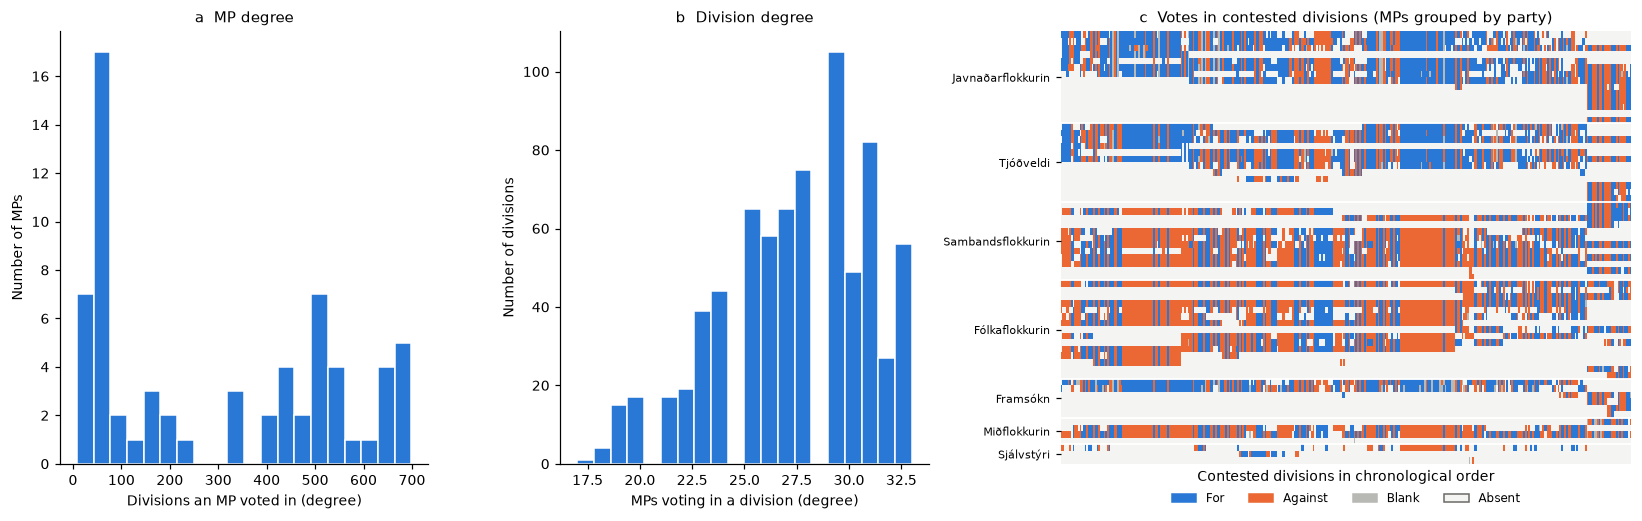

In [10]:
# Figure 1 -- structural summary of the bipartite network
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.55]})
ax[0].hist(mp_deg, bins=20, color=C_FOR, edgecolor="white")
ax[0].set(xlabel="Divisions an MP voted in (degree)", ylabel="Number of MPs", title="a  MP degree")
ax[1].hist(div_deg, bins=20, color=C_FOR, edgecolor="white")
ax[1].set(xlabel="MPs voting in a division (degree)", ylabel="Number of divisions", title="b  Division degree")

order_mp = parties.loc[Mc.index].map({p: i for i, p in enumerate(N.PARTY_ORDER)}).sort_values(kind="stable").index
cols = vdates.loc[Mc.columns].sort_values().index
Z = Mc.loc[order_mp, cols].to_numpy()
ax[2].imshow(np.ma.masked_invalid(Z), aspect="auto", interpolation="nearest", vmin=-1, vmax=1,
             cmap=ListedColormap([C_AGAINST, C_BLANK, C_FOR]))
ax[2].set_facecolor(C_ABSENT)
pp = parties.loc[order_mp].to_numpy()
bounds = [0] + [i for i in range(1, len(pp)) if pp[i] != pp[i - 1]] + [len(pp)]
for b_ in bounds[1:-1]:
    ax[2].axhline(b_ - 0.5, color="white", lw=1.2)
ax[2].set_yticks([(a + b_ - 1) / 2 for a, b_ in zip(bounds[:-1], bounds[1:])])
ax[2].set_yticklabels([pp[a] for a in bounds[:-1]], fontsize=7)
ax[2].set(xlabel="Contested divisions in chronological order", title="c  Votes in contested divisions (MPs grouped by party)")
ax[2].set_xticks([])
ax[2].spines[["left", "bottom"]].set_visible(False)
ax[2].legend(handles=[Patch(color=C_FOR, label="For"), Patch(color=C_AGAINST, label="Against"),
                      Patch(color=C_BLANK, label="Blank"), Patch(facecolor=C_ABSENT, edgecolor=MUTED, label="Absent")],
             ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.04), fontsize=8)
fig.tight_layout()
save_fig(fig, "fig1_bipartite_structure")
plt.show()

**Figure 1.** Structure of the MP–division bipartite network (divisions in the speech window with a per-MP breakdown). (a) Number of divisions each MP voted in: a wide spread, because some MPs served the whole window and others only a short time. (b) Number of MPs voting in each division. (c) Each row is an MP (grouped by party), each column a contested division in time order; absent MPs are blank. Blocks of identical colour within a party's rows show how cohesively the party votes, and the staggered blank areas show who was in parliament when.

## 5. Network B — MP–MP voting-similarity network

**Similarity** for a pair of MPs *(i, j)*:

$$\text{sim}(i,j)=\frac{\#\{\text{contested divisions where } i \text{ and } j \text{ cast the same valid vote}\}}{\#\{\text{contested divisions where both cast a valid vote}\}}$$

Only contested divisions count, and a division only counts for a pair if **both** voted For or Against; absence and blank votes drop out of numerator *and* denominator. A pair's `n_shared_divisions` is that denominator. Pairs whose denominator is small are noisy, so edges are only drawn when `n_shared_divisions ≥ 40` (sensitivity: 20 and 60). **Missing votes affect precision, not the value:** a pair with 5 shared divisions can have the same similarity as one with 200, but the first is far less reliable, which is why the overlap threshold exists.

The *full* pairwise table (every MP pair, including pairs that fail the threshold or never overlapped, whose similarity is NaN) is saved for the speech workstream.

> **Caution.** Agreement on contested divisions is *voting* similarity. It is shaped by party discipline and government/opposition roles, so it is not evidence of shared ideology or shared views.

In [11]:
pairs = N.pairwise_table(Mc, parties, thresholds=MIN_OVERLAPS)
print(f"{len(pairs)} MP pairs from {Mc.shape[0]} MPs and {Mc.shape[1]} contested divisions")
display(pairs.head())

rows = {}
for t in MIN_OVERLAPS:
    ok = pairs[f"meets_min_overlap_{t}"]
    rows[f"min overlap {t}"] = {"pairs kept": int(ok.sum()), "share of all pairs": round(float(ok.mean()), 3),
                                "MPs with >= 1 edge": len(set(pairs[ok].mp_id_1) | set(pairs[ok].mp_id_2)),
                                "median shared divisions (kept pairs)": float(pairs[ok].n_shared_divisions.median())}
display(pd.DataFrame(rows))
print("pairs that never overlapped (similarity undefined):", int((pairs.n_shared_divisions == 0).sum()))
print("similarity of pairs meeting the main threshold:",
      pairs.loc[pairs.meets_min_overlap_40, "similarity"].describe().round(3).to_dict())
R["pairs"] = {"n_mps": int(Mc.shape[0]), "n_pairs": len(pairs), "n_never_overlapped": int((pairs.n_shared_divisions == 0).sum()),
              "kept_by_threshold": {str(t): int(pairs[f"meets_min_overlap_{t}"].sum()) for t in MIN_OVERLAPS}}

2145 MP pairs from 66 MPs and 333 contested divisions


,mp_id_1,mp_id_2,similarity,n_shared_divisions,n_matching,meets_min_overlap_20,meets_min_overlap_40,meets_min_overlap_60,party_1,party_2,same_party
0,MPID000001,MPID000002,0.938776,49,46,True,True,False,Fólkaflokkurin,Fólkaflokkurin,True
1,MPID000001,MPID000003,0.941860,86,81,True,True,True,Fólkaflokkurin,Fólkaflokkurin,True
2,MPID000001,MPID000004,1.000000,291,291,True,True,True,Fólkaflokkurin,Fólkaflokkurin,True
3,MPID000001,MPID000005,1.000000,188,188,True,True,True,Fólkaflokkurin,Fólkaflokkurin,True
4,MPID000001,MPID000006,0.995050,202,201,True,True,True,Fólkaflokkurin,Fólkaflokkurin,True


,min overlap 20,min overlap 40,min overlap 60
pairs kept,1081.000,712.000,623.00
share of all pairs,0.504,0.332,0.29
MPs with >= 1 edge,58.000,41.000,39.00
median shared divisions (kept pairs),75.000,159.000,172.00


pairs that never overlapped (similarity undefined): 713
similarity of pairs meeting the main threshold: {'count': 712.0, 'mean': 0.537, 'std': 0.406, 'min': 0.0, '25%': 0.162, '50%': 0.333, '75%': 0.985, 'max': 1.0}


## 6. Network analysis of the thresholded similarity network

The main network keeps pairs with ≥ 40 shared contested divisions; edge **weight = similarity**. Notes on the measures:

* **Degree** = number of other MPs an MP is connected to. In this network it mostly reflects *how long an MP served* (more divisions → more partners clearing the overlap threshold), not popularity.
* **Strength** = sum of an MP's edge weights: how much agreement an MP has in total, again inflated by long service. **Mean similarity** (strength ÷ degree) corrects for that.
* **Betweenness** is computed with edge *length* = 1 / similarity, so strongly agreeing MPs are "close". It then identifies MPs lying on many shortest agreement-paths between others, i.e. a *bridging* position between blocks of MPs. It does not mean influence or importance.
* **Louvain communities** are groups that agree more internally than expected; **modularity Q** measures how strongly the partition separates the network (it does not say the partition is *correct*). Louvain is stochastic, so it is run with 20 seeds, the best-Q partition is kept and run-to-run stability is reported as NMI.
* **Party NMI** compares the communities with party membership (0 = unrelated, 1 = identical). Isolated MPs (no edge passes the threshold) are left out of NMI.

In [12]:
G = N.similarity_graph(pairs, MAIN_OVERLAP, parties, names, Mc.index)
gs = N.graph_summary(G)
display(pd.Series(gs, name="main network").to_frame())
isolates = [n for n, d in G.degree() if d == 0]
print(f"{len(isolates)} MPs have no edge at min overlap {MAIN_OVERLAP}; "
      f"their contested-division counts: {sorted(Mc.notna().sum(axis=1).loc[isolates].tolist())}")
print("isolates by period of service:", mp_periods.reindex(isolates).fillna("no vote cast").value_counts().to_dict())
R["graph_main"] = gs

,main network
n_nodes,66.000000
n_edges,712.000000
density,0.331935
n_components,26.000000
largest_component,41.000000
n_isolates,25.000000
mean_degree,21.575758
mean_edge_weight,0.537094


25 MPs have no edge at min overlap 40; their contested-division counts: [0, 1, 2, 3, 4, 14, 14, 17, 20, 20, 22, 23, 24, 24, 25, 25, 26, 26, 26, 26, 26, 26, 26, 33, 36]
isolates by period of service: {'P2': 15, 'P1': 6, 'both': 4}


In [13]:
# node-level metrics
strength = dict(G.degree(weight="weight"))
degree = dict(G.degree())
betw = nx.betweenness_centrality(G, weight="length", normalized=True)
best_part, mods, stab = N.louvain_runs(G, range(SEED, SEED + 20))
nonisol_comms = sorted([c for c in best_part if any(degree[n] > 0 for n in c)], key=len, reverse=True)
comm_of = {n: k for k, c in enumerate(nonisol_comms) for n in c}

nm = pd.DataFrame({"mp_id": list(G.nodes)})
nm["name"] = nm.mp_id.map(names)
nm["party"] = nm.mp_id.map(parties)
nm["n_contested_divisions_voted"] = nm.mp_id.map(Mc.notna().sum(axis=1)).astype(int)
nm["degree"] = nm.mp_id.map(degree)
nm["strength"] = nm.mp_id.map(strength)
nm["mean_similarity"] = (nm.strength / nm.degree.where(nm.degree > 0))
nm["betweenness"] = nm.mp_id.map(betw)
nm["community"] = nm.mp_id.map(comm_of).fillna(-1).astype(int)     # -1 = isolated (no edge)
display(nm.sort_values("strength", ascending=False).head(8).round(3))
print("most 'between' MPs:")
display(nm.sort_values("betweenness", ascending=False).head(6)[["name", "party", "degree", "strength", "betweenness", "community"]].round(3))

louv = {"n_communities_nonisolated": len(nonisol_comms), "community_sizes": [len(c) for c in nonisol_comms],
        "modularity_best_of_20": float(max(mods)), "modularity_range_20_seeds": [float(min(mods)), float(max(mods))],
        "mean_pairwise_NMI_between_seeds": stab,
        "party_NMI": N.party_nmi(G, best_part),
        "modularity_of_party_partition": nx.community.modularity(G, N.party_partition(G), weight="weight")}
print(louv)
R["louvain_main"] = louv
display(pd.crosstab(nm[nm.community >= 0].party, nm[nm.community >= 0].community).reindex(N.PARTY_ORDER).fillna(0).astype(int))

,mp_id,name,party,n_contested_divisions_voted,degree,strength,mean_similarity,betweenness,community
0,MPID000001,Beinir Johannesen,Fólkaflokkurin,316,40,24.972,0.624,0.008,0
20,MPID000021,Erhard Joensen,Sambandsflokkurin,311,40,24.880,0.622,0.000,0
50,MPID000055,Steffan Klein Poulsen,Miðflokkurin,310,40,24.690,0.617,0.001,0
21,MPID000022,Edva Jacobsen,Sambandsflokkurin,298,39,24.280,0.623,0.006,0
3,MPID000004,Jógvan á Lakjuni,Fólkaflokkurin,306,39,24.242,0.622,0.002,0
18,MPID000019,Johan Dahl,Sambandsflokkurin,294,39,24.058,0.617,0.000,0
17,MPID000018,Rósa Samuelsen,Sambandsflokkurin,235,38,23.258,0.612,0.017,0
16,MPID000017,Frimodt Rasmussen,Sambandsflokkurin,251,38,22.987,0.605,0.001,0


most 'between' MPs:


,name,party,degree,strength,betweenness,community
2,Jørgen Niclasen,Fólkaflokkurin,26,15.479,0.067,0
13,Magnus Rasmussen,Sambandsflokkurin,35,20.576,0.051,0
31,Eyðgunn Samuelsen,Javnaðarflokkurin,36,17.456,0.035,1
44,Bjarni Kárason Petersen,Framsókn,38,17.250,0.035,1
30,Bjarni Hammer,Javnaðarflokkurin,39,19.419,0.025,1
14,Helgi Abrahamsen,Sambandsflokkurin,35,22.344,0.024,0


{'n_communities_nonisolated': 2, 'community_sizes': [24, 17], 'modularity_best_of_20': 0.32249086835123286, 'modularity_range_20_seeds': [0.32249086835123286, 0.32249086835123286], 'mean_pairwise_NMI_between_seeds': 1.0, 'party_NMI': 0.5731902734567265, 'modularity_of_party_partition': 0.10321611481339042}


community,0,1
party,,
Javnaðarflokkurin,0,8
Tjóðveldi,0,7
Sambandsflokkurin,8,0
Fólkaflokkurin,13,0
Framsókn,0,2
Miðflokkurin,2,0
Sjálvstýri,1,0


In [14]:
# within- vs between-party similarity and party-by-party structure
wb = {str(t): N.within_between(pairs, t) for t in MIN_OVERLAPS}
display(pd.DataFrame(wb).T.round(3))
R["within_between"] = wb

pm = pairs[pairs.meets_min_overlap_40].copy()
flip = pm.rename(columns={"party_1": "party_2", "party_2": "party_1"})
long = pd.concat([pm[["party_1", "party_2", "similarity"]], flip[["party_1", "party_2", "similarity"]]])
pp_mean = long.groupby(["party_1", "party_2"]).similarity.mean().unstack().reindex(index=N.PARTY_ORDER, columns=N.PARTY_ORDER)
pp_n = long.groupby(["party_1", "party_2"]).size().unstack().reindex(index=N.PARTY_ORDER, columns=N.PARTY_ORDER)
for p in N.PARTY_ORDER:
    if pd.notna(pp_n.loc[p, p]):
        pp_n.loc[p, p] //= 2                       # within-party pairs were counted in both orders
print("mean similarity between parties (pairs with >= 40 shared divisions):")
display(pp_mean.round(2))
print("number of MP pairs behind each cell:")
display(pp_n.fillna(0).astype(int))

top_cross = (pm[~pm.same_party].assign(name_1=lambda d: d.mp_id_1.map(names), name_2=lambda d: d.mp_id_2.map(names))
             .sort_values(["similarity", "n_shared_divisions"], ascending=False)
             [["name_1", "party_1", "name_2", "party_2", "similarity", "n_shared_divisions"]].head(12))
print("most similar cross-party pairs:")
display(top_cross.round(3))

,n_pairs,n_within,n_between,mean_within,mean_between,gap_within_minus_between
20,1081.0,192.0,889.0,0.981,0.486,0.495
40,712.0,123.0,589.0,0.984,0.444,0.541
60,623.0,106.0,517.0,0.984,0.442,0.542


mean similarity between parties (pairs with >= 40 shared divisions):


party_2,Javnaðarflokkurin,Tjóðveldi,Sambandsflokkurin,Fólkaflokkurin,Framsókn,Miðflokkurin,Sjálvstýri
party_1,,,,,,,
Javnaðarflokkurin,0.98,0.82,0.23,0.20,0.74,0.19,0.19
Tjóðveldi,0.82,0.98,0.07,0.06,0.85,0.05,0.04
Sambandsflokkurin,0.23,0.07,0.99,0.97,0.21,0.97,0.99
Fólkaflokkurin,0.20,0.06,0.97,0.99,0.18,0.98,0.99
Framsókn,0.74,0.85,0.21,0.18,0.98,0.19,0.21
Miðflokkurin,0.19,0.05,0.97,0.98,0.19,1.00,1.00
Sjálvstýri,0.19,0.04,0.99,0.99,0.21,1.00,NaN


number of MP pairs behind each cell:


party_2,Javnaðarflokkurin,Tjóðveldi,Sambandsflokkurin,Fólkaflokkurin,Framsókn,Miðflokkurin,Sjálvstýri
party_1,,,,,,,
Javnaðarflokkurin,26,52,62,87,16,16,7
Tjóðveldi,52,19,54,73,14,14,6
Sambandsflokkurin,62,54,27,89,16,16,7
Fólkaflokkurin,87,73,89,49,21,23,8
Framsókn,16,14,16,21,1,4,2
Miðflokkurin,16,14,16,23,4,1,2
Sjálvstýri,7,6,7,8,2,2,0


most similar cross-party pairs:


,name_1,party_1,name_2,party_2,similarity,n_shared_divisions
209,Jógvan á Lakjuni,Fólkaflokkurin,Edva Jacobsen,Sambandsflokkurin,1.0,297
20,Beinir Johannesen,Fólkaflokkurin,Edva Jacobsen,Sambandsflokkurin,1.0,286
238,Jógvan á Lakjuni,Fólkaflokkurin,Steffan Klein Poulsen,Miðflokkurin,1.0,282
1183,Edva Jacobsen,Sambandsflokkurin,Steffan Klein Poulsen,Miðflokkurin,1.0,280
204,Jógvan á Lakjuni,Fólkaflokkurin,Frimodt Rasmussen,Sambandsflokkurin,1.0,249
15,Beinir Johannesen,Fólkaflokkurin,Frimodt Rasmussen,Sambandsflokkurin,1.0,237
237,Jógvan á Lakjuni,Fólkaflokkurin,Bill Justinussen,Miðflokkurin,1.0,235
205,Jógvan á Lakjuni,Fólkaflokkurin,Rósa Samuelsen,Sambandsflokkurin,1.0,232
207,Jógvan á Lakjuni,Fólkaflokkurin,Jaspur Langgaard,Sambandsflokkurin,1.0,231
1182,Edva Jacobsen,Sambandsflokkurin,Bill Justinussen,Miðflokkurin,1.0,230


In [15]:
# sensitivity of the network to the overlap threshold (and to the blank-vote treatment, section 7)
def analyse(Mx, thr, include_blank=False, label="", seeds=range(SEED, SEED + 10)):
    """Pairwise table -> thresholded graph -> headline statistics for one analysis scenario."""
    Mx = Mx.loc[Mx.notna().any(axis=1)]                 # drop MPs with no vote in this subset
    px = parties.loc[Mx.index]
    pr = N.pairwise_table(Mx, px, include_blank=include_blank, thresholds=(thr,))
    wbx = N.within_between(pr, thr)
    Gx = N.similarity_graph(pr, thr, px, names, Mx.index)
    gsx = N.graph_summary(Gx)
    out = {"scenario": label, "min_overlap": thr, "n_divisions": int(Mx.shape[1]), "n_mps": int(Mx.shape[0]),
           "n_edges": gsx["n_edges"], "density": gsx["density"], "n_components": gsx["n_components"],
           "n_isolates": gsx["n_isolates"], "n_within_pairs": wbx["n_within"], "n_between_pairs": wbx["n_between"],
           "mean_within": wbx["mean_within"], "mean_between": wbx["mean_between"],
           "gap_within_minus_between": wbx["gap_within_minus_between"]}
    if gsx["n_edges"] > 0:
        part, mods_, stab_ = N.louvain_runs(Gx, seeds)
        out.update({"louvain_n_communities": sum(1 for c in part if any(Gx.degree(n) > 0 for n in c)),
                    "louvain_modularity": float(max(mods_)), "louvain_stability_NMI": stab_,
                    "party_NMI": N.party_nmi(Gx, part),
                    "party_partition_modularity": nx.community.modularity(Gx, N.party_partition(Gx), weight="weight")})
    return out

scen = [analyse(Mc, t, label=f"main design, min overlap {t}") for t in MIN_OVERLAPS]
display(pd.DataFrame(scen).set_index("scenario").round(3).T)

scenario,"main design, min overlap 20","main design, min overlap 40","main design, min overlap 60"
min_overlap,20.000,40.000,60.000
n_divisions,333.000,333.000,333.000
n_mps,65.000,65.000,65.000
n_edges,1081.000,712.000,623.000
density,0.520,0.342,0.300
n_components,8.000,25.000,27.000
n_isolates,7.000,24.000,26.000
n_within_pairs,192.000,123.000,106.000
n_between_pairs,889.000,589.000,517.000
mean_within,0.981,0.984,0.984


## 7. Statistical validation and robustness

Everything above is *descriptive*. Two questions need a test:

1. **Is the party gap bigger than chance?** *Party-label permutation test:* shuffle the party labels across MPs (party sizes preserved), recompute *mean within-party minus mean between-party similarity*, repeat. This tests whether party labels carry information about voting similarity.
2. **Do the MPs' voting patterns carry structure beyond what each division's overall outcome implies?** *Within-division shuffle null:* in every contested division, randomly reassign the For/Against votes among the MPs who voted For/Against in that division. This **keeps** each division's participants, its For/Against totals and where the blanks and absences are, and **destroys** everything MP-specific. Observed network statistics are compared with the same statistics under this null.

Both are one-sided Monte Carlo tests with the +1 correction, `p = (1 + #{null ≥ observed}) / (1 + n_perm)`, so the smallest possible p-value is `1 / (1 + n_perm)`. **These tests show that structure exists; they do not show *why* it exists** (party discipline, government vs. opposition, or ideology are not separated here).

Runtime is estimated first, from a small timed batch.

In [16]:
A = Mc.to_numpy()
labels = pd.Categorical(parties.loc[Mc.index], categories=N.PARTY_ORDER).codes
sh, ma = N.agreement_counts(A)
ii, jj, sim_obs = N.upper_arrays(sh, ma, MAIN_OVERLAP)
same_obs = labels[ii] == labels[jj]
gap_obs = N.gap(sim_obs, same_obs)

def graph_stats(shared, match, min_overlap=MAIN_OVERLAP):
    """Louvain modularity and party NMI of the thresholded similarity graph (single seed)."""
    a, b, s = N.upper_arrays(shared, match, min_overlap)
    g = nx.Graph()
    g.add_nodes_from(range(shared.shape[0]))
    g.add_weighted_edges_from(zip(a, b, s))
    part = nx.community.louvain_communities(g, weight="weight", seed=SEED)
    nodes = [n for n, d in g.degree() if d > 0]
    lab = {n: k for k, c in enumerate(part) for n in c}
    from sklearn.metrics import normalized_mutual_info_score as nmi
    return {"louvain_Q": nx.community.modularity(g, part, weight="weight"),
            "party_NMI": nmi(labels[nodes], [lab[n] for n in nodes])}

obs_graph = graph_stats(sh, ma)
PERM_PARTY, PERM_DIVISION = 10_000, 1_000

t0 = time.perf_counter()
N.permute_party_gap(ii, jj, sim_obs, labels, 200, np.random.default_rng(SEED))
est_party = (time.perf_counter() - t0) / 200 * PERM_PARTY
t0 = time.perf_counter()
N.division_null(A, labels, MAIN_OVERLAP, 10, np.random.default_rng(SEED), graph_fn=graph_stats)
est_div = (time.perf_counter() - t0) / 10 * PERM_DIVISION
print(f"estimated runtime: party-label test {est_party:.0f} s for {PERM_PARTY:,} permutations; "
      f"within-division null {est_div:.0f} s for {PERM_DIVISION:,} permutations")

estimated runtime: party-label test 1 s for 10,000 permutations; within-division null 65 s for 1,000 permutations


In [17]:
# (1) party-label permutation test
rng_party = np.random.default_rng(SEED)
null_party = N.permute_party_gap(ii, jj, sim_obs, labels, PERM_PARTY, rng_party)
p_party = N.empirical_p(gap_obs, null_party)
print(f"observed within-minus-between gap = {gap_obs:.3f}; null mean {null_party.mean():.3f}, sd {null_party.std():.3f}, "
      f"max {null_party.max():.3f}; one-sided p = {p_party:.4f} ({PERM_PARTY:,} permutations, seed {SEED})")

# (2) within-division shuffle null
rng_div = np.random.default_rng(SEED + 1)
null_div = N.division_null(A, labels, MAIN_OVERLAP, PERM_DIVISION, rng_div, graph_fn=graph_stats)
obs = {"mean_sim": sim_obs.mean(), "sd_sim": sim_obs.std(ddof=1), "gap": gap_obs, **obs_graph}
tab = pd.DataFrame({"observed": obs, "null mean": null_div.mean(), "null sd": null_div.std(),
                    "null max": null_div.max(),
                    "one-sided p": {k: N.empirical_p(obs[k], null_div[k]) for k in obs}})
display(tab.round(4))
print(f"{PERM_DIVISION:,} within-division permutations, seed {SEED + 1}. "
      "mean_sim is a check, not a test: the null preserves each division's totals, so it must match the observed mean.")
R["validation"] = {"party_label_permutation": {"n_perm": PERM_PARTY, "seed": SEED, "observed_gap": gap_obs,
                                               "null_mean": float(null_party.mean()), "null_sd": float(null_party.std()),
                                               "null_max": float(null_party.max()), "p_one_sided": p_party},
                   "within_division_shuffle": {"n_perm": PERM_DIVISION, "seed": SEED + 1,
                                               "table": tab.round(6).to_dict(orient="index")}}

observed within-minus-between gap = 0.541; null mean 0.000, sd 0.042, max 0.252; one-sided p = 0.0001 (10,000 permutations, seed 2805)


,observed,null mean,null sd,null max,one-sided p
mean_sim,0.5371,0.5374,0.0011,0.5408,0.6154
sd_sim,0.4058,0.0503,0.0017,0.0586,0.0010
gap,0.5406,0.0012,0.0046,0.0153,0.0010
louvain_Q,0.3225,0.0368,0.0018,0.0426,0.0010
party_NMI,0.5732,0.0632,0.0207,0.1273,0.0010


1,000 within-division permutations, seed 2806. mean_sim is a check, not a test: the null preserves each division's totals, so it must match the observed mean.


In [18]:
# sensitivity: blank votes, stricter contested rule, the party-switcher, and each parliamentary period separately
Mc3 = M_all.loc[:, N.contested_mask(M_all, min_minority=3)]
scen2 = [
    analyse(Mc, MAIN_OVERLAP, include_blank=True, label="blank votes count as a third category"),
    analyse(Mc3, MAIN_OVERLAP, label=f"stricter contested rule (minority >= 3; {Mc3.shape[1]} divisions)"),
    analyse(Mc3, 20, label="stricter rule, min overlap 20"),
    analyse(Mc.drop(index=switchers), MAIN_OVERLAP, label="excluding the party-switching MP"),
    analyse(Mc.loc[:, period.loc[Mc.columns] == "P1"], MAIN_OVERLAP, label="period P1 only (before the break)"),
    analyse(Mc.loc[:, period.loc[Mc.columns] == "P2"], 20, label="period P2 only (after the break), min overlap 20"),
]
scenarios = pd.DataFrame(scen + scen2)
display(scenarios.set_index("scenario").round(3).T)

pb = N.pairwise_table(Mc, parties, include_blank=True, thresholds=(MAIN_OVERLAP,))
both = pairs.n_shared_divisions.ge(MAIN_OVERLAP) & pb.n_shared_divisions.ge(MAIN_OVERLAP)
rho = stats.spearmanr(pairs.loc[both, "similarity"], pb.loc[both, "similarity"])[0]
print(f"Spearman correlation of pair similarity, blanks excluded vs. blanks as a category: {rho:.3f} ({int(both.sum())} pairs)")
R["blank_sensitivity_spearman"] = float(rho)
R["scenarios"] = scenarios.round(6).to_dict(orient="records")

scenario,"main design, min overlap 20","main design, min overlap 40","main design, min overlap 60",blank votes count as a third category,stricter contested rule (minority >= 3; 313 divisions),"stricter rule, min overlap 20",excluding the party-switching MP,period P1 only (before the break),"period P2 only (after the break), min overlap 20"
min_overlap,20.000,40.000,60.000,40.000,40.000,20.000,40.000,40.000,20.000
n_divisions,333.000,333.000,333.000,333.000,313.000,313.000,333.000,307.000,26.000
n_mps,65.000,65.000,65.000,65.000,65.000,65.000,64.000,50.000,34.000
n_edges,1081.000,712.000,623.000,713.000,701.000,955.000,679.000,692.000,345.000
density,0.520,0.342,0.300,0.343,0.337,0.459,0.337,0.565,0.615
n_components,8.000,25.000,27.000,25.000,25.000,13.000,25.000,11.000,7.000
n_isolates,7.000,24.000,26.000,24.000,24.000,12.000,24.000,10.000,6.000
n_within_pairs,192.000,123.000,106.000,123.000,120.000,179.000,116.000,120.000,67.000
n_between_pairs,889.000,589.000,517.000,590.000,581.000,776.000,563.000,572.000,278.000
mean_within,0.981,0.984,0.984,0.974,0.986,0.980,0.986,0.986,0.983


Spearman correlation of pair similarity, blanks excluded vs. blanks as a category: 0.993 (712 pairs)


**Exploratory vs. tested.** The permutation / shuffle results above are the only *tested* claims in this notebook. Degree, strength, betweenness, the community structure, the party-by-party table and the single most-similar cross-party pairs are *descriptive*. The sensitivity table shows how much the headline numbers move when design choices change; a conclusion that only holds for one row of it should not be trusted.

## 8. Figures

Figure 1 (bipartite structure) was produced in section 4. The figures below are saved to `network_analysis/outputs/figures/` as PNG (300 dpi) and PDF.

Party is shown by **colour and marker shape** (seven parties are too many for colour alone). Network layouts are Kamada–Kawai with edge length = 1 / similarity, used only to make the blocks visible; **node positions carry no quantitative meaning**. Because the thresholded graph is almost complete, the drawn edges are a **disparity-filter backbone** (course Week 4) used for visualisation only — every statistic in this notebook uses the full weighted graph. Isolated MPs (no edge at the threshold) are not drawn.

In [19]:
Gc = G.subgraph([n for n in G if G.degree(n) > 0]).copy()
for a_ in (0.05, 0.1, 0.2):
    print(f"disparity filter alpha={a_}: {N.disparity_filter(Gc, a_).number_of_edges()} of {Gc.number_of_edges()} edges survive")
BACKBONE_ALPHA = 0.2     # at the usual 0.05 no edge survives: the graph is almost complete with a strongly bimodal weight distribution
H = N.disparity_filter(Gc, BACKBONE_ALPHA)
R["figures"] = {"backbone_alpha": BACKBONE_ALPHA, "backbone_edges": H.number_of_edges(), "backbone_source_edges": Gc.number_of_edges(),
                "nodes_drawn": Gc.number_of_nodes()}

pos = nx.kamada_kawai_layout(Gc, weight="length")       # layout only; deterministic
smax = max(strength[n] for n in Gc)
size_of = {n: 30 + 130 * strength[n] / smax for n in Gc}
top_label = nm.set_index("mp_id").loc[list(Gc.nodes)].betweenness.nlargest(6).index

def draw_network(ax, color_of, title):
    nx.draw_networkx_edges(H, pos, ax=ax, width=[0.3 + 1.0 * d["weight"] for *_, d in H.edges(data=True)],
                           edge_color="#8a8a86", alpha=0.3)
    for p in N.PARTY_ORDER:
        ns = [n for n in Gc if Gc.nodes[n]["party"] == p]
        if ns:
            ax.scatter(*zip(*[pos[n] for n in ns]), s=[size_of[n] for n in ns], c=[color_of[n] for n in ns],
                       marker=N.PARTY_MARKERS[p], edgecolors="white", linewidths=0.9, zorder=3)
    for n in top_label:
        ax.annotate(names[n], pos[n], xytext=(6, 6), textcoords="offset points", fontsize=7, color=INK, zorder=4,
                    bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.85})
    ax.set_title(title, loc="left")
    ax.set_axis_off()

def party_handles(color_of_party=None):
    present = [p for p in N.PARTY_ORDER if p in set(nm[nm.degree > 0].party)]
    return [Line2D([0], [0], marker=N.PARTY_MARKERS[p], ls="", markersize=8, markeredgecolor="white",
                   markerfacecolor=(color_of_party or N.PARTY_COLORS)[p], label=p) for p in present]

disparity filter alpha=0.05: 0 of 712 edges survive
disparity filter alpha=0.1: 20 of 712 edges survive
disparity filter alpha=0.2: 279 of 712 edges survive


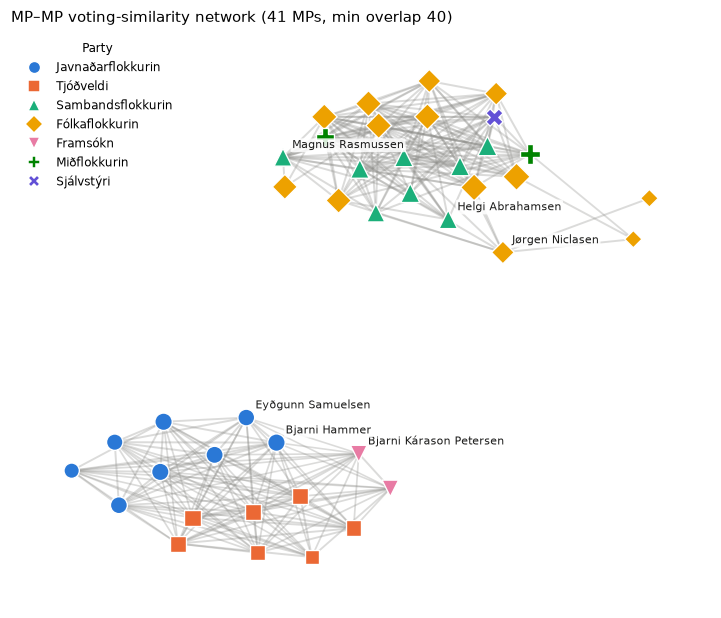

In [20]:
# Figure 2 -- the MP-MP voting-similarity network, coloured by party
fig, ax = plt.subplots(figsize=(8.2, 6.8))
draw_network(ax, {n: N.PARTY_COLORS[Gc.nodes[n]["party"]] for n in Gc},
             f"MP–MP voting-similarity network ({Gc.number_of_nodes()} MPs, min overlap {MAIN_OVERLAP})")
ax.legend(handles=party_handles(), title="Party", loc="upper left", fontsize=8, title_fontsize=8)
save_fig(fig, "fig2_voting_similarity_network")
plt.show()

**Figure 2.** MP–MP voting-similarity network for contested divisions in the speech window. Nodes are MPs (colour and marker = party, size = weighted degree/strength); edges are the disparity-filter backbone of pairs with ≥ 40 shared divisions, thicker = more similar. The six labelled MPs have the highest betweenness (bridging position, not influence). MPs with no pair reaching 40 shared divisions are not shown.

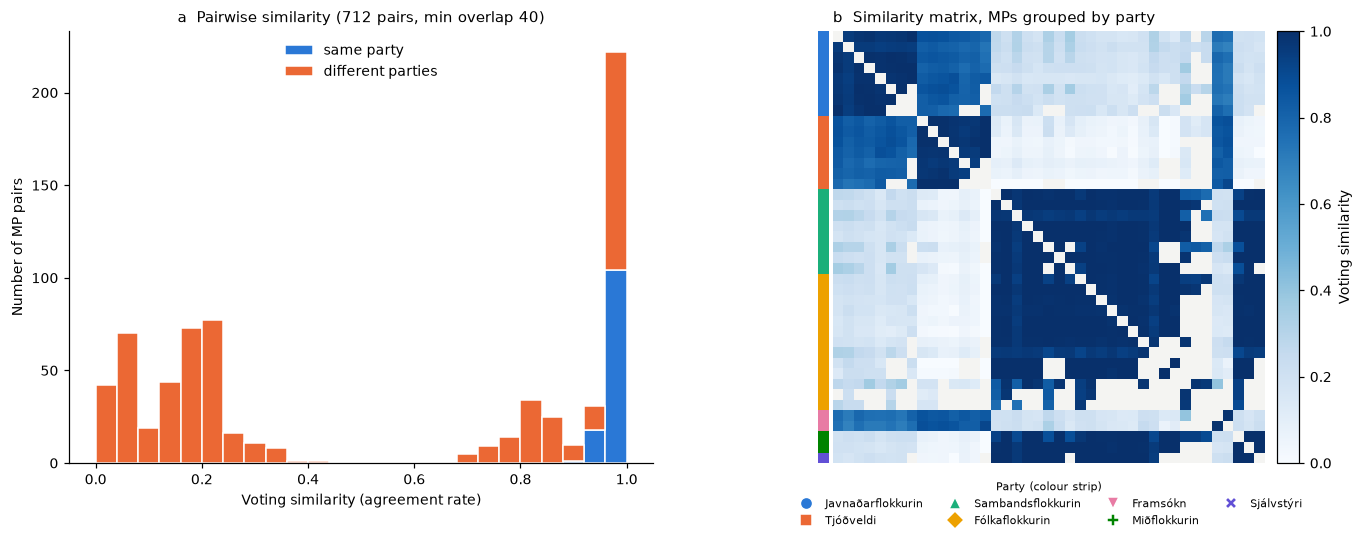

In [21]:
# Figure 3 -- distribution of pairwise similarity, and the similarity matrix ordered by party
pk = pairs[pairs.meets_min_overlap_40]
C_WITHIN, C_BETWEEN = C_FOR, C_AGAINST
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5), gridspec_kw={"width_ratios": [1, 1.1]})
bins = np.linspace(0, 1, 26)
ax[0].hist([pk[pk.same_party].similarity, pk[~pk.same_party].similarity], bins=bins, stacked=True,
           color=[C_WITHIN, C_BETWEEN], edgecolor="white", label=["same party", "different parties"])
ax[0].set(xlabel="Voting similarity (agreement rate)", ylabel="Number of MP pairs",
          title=f"a  Pairwise similarity ({len(pk)} pairs, min overlap {MAIN_OVERLAP})")
ax[0].legend(loc="upper center")

order = sorted(Gc.nodes, key=lambda n: (N.PARTY_ORDER.index(Gc.nodes[n]["party"]), -strength[n]))
ix = {n: i for i, n in enumerate(order)}
S = np.full((len(order), len(order)), np.nan)
for u, v, d in Gc.edges(data=True):
    S[ix[u], ix[v]] = S[ix[v], ix[u]] = d["weight"]
cm_ = plt.get_cmap("Blues").copy(); cm_.set_bad(C_ABSENT)
im = ax[1].imshow(np.ma.masked_invalid(S), cmap=cm_, vmin=0, vmax=1, interpolation="nearest")
ax[1].set_xticks([]); ax[1].set_yticks([])
ax[1].set_title("b  Similarity matrix, MPs grouped by party", loc="left")
ax[1].spines[["left", "bottom"]].set_visible(False)
strip = ax[1].inset_axes([-0.035, 0, 0.025, 1])
from matplotlib.colors import to_rgb
strip.imshow(np.array([[to_rgb(N.PARTY_COLORS[Gc.nodes[n]["party"]])] for n in order]), aspect="auto")
strip.set_axis_off()
cb = fig.colorbar(im, ax=ax[1], fraction=0.04, pad=0.02); cb.set_label("Voting similarity")
ax[1].legend(handles=party_handles(), title="Party (colour strip)", loc="upper center",
             bbox_to_anchor=(0.5, -0.02), ncol=4, fontsize=7, title_fontsize=7)
fig.tight_layout()
save_fig(fig, "fig3_similarity_distribution")
plt.show()

**Figure 3.** (a) Distribution of pairwise voting similarity for pairs with ≥ 40 shared contested divisions, split by whether the two MPs belong to the same party. (b) The same similarities as a matrix, MPs grouped by party (colour strip) and ordered by strength within party; grey = pair below the overlap threshold.

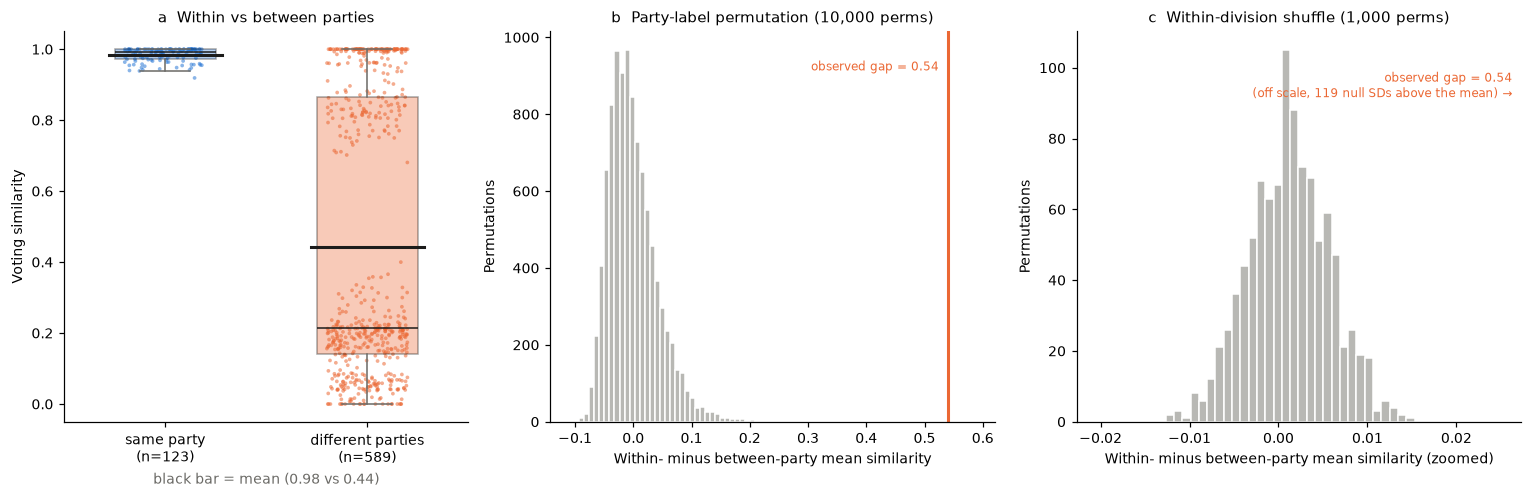

In [22]:
# Figure 4 -- within- vs between-party similarity, and the two null models
rng_plot = np.random.default_rng(SEED)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
w_, b_ = pk[pk.same_party].similarity.to_numpy(), pk[~pk.same_party].similarity.to_numpy()
bp_ = ax[0].boxplot([w_, b_], widths=0.5, showfliers=False, patch_artist=True,
                    medianprops={"color": INK}, boxprops={"alpha": 0.35}, whiskerprops={"color": MUTED}, capprops={"color": MUTED})
for patch, c in zip(bp_["boxes"], (C_WITHIN, C_BETWEEN)):
    patch.set_facecolor(c)
for k, (v_, c) in enumerate(((w_, C_WITHIN), (b_, C_BETWEEN)), start=1):
    ax[0].scatter(k + rng_plot.uniform(-0.2, 0.2, len(v_)), v_, s=6, color=c, alpha=0.55, edgecolors="none")
    ax[0].plot([k - 0.28, k + 0.28], [v_.mean()] * 2, color=INK, lw=2)
ax[0].set_xticks([1, 2]); ax[0].set_xticklabels([f"same party\n(n={len(w_)})", f"different parties\n(n={len(b_)})"])
ax[0].set(ylabel="Voting similarity", title="a  Within vs between parties")
ax[0].set_xlabel(f"black bar = mean ({w_.mean():.2f} vs {b_.mean():.2f})", color=MUTED)

ax[1].hist(null_party, bins=40, color=C_BLANK, edgecolor="white")
ax[1].axvline(gap_obs, color=C_AGAINST, lw=2)
ax[1].annotate(f"observed gap = {gap_obs:.2f}", (gap_obs, ax[1].get_ylim()[1] * 0.9), xytext=(-6, 0),
               textcoords="offset points", ha="right", color=C_AGAINST, fontsize=8)
ax[1].set(xlabel="Within- minus between-party mean similarity", ylabel="Permutations",
          title=f"b  Party-label permutation ({PERM_PARTY:,} perms)")
ax[1].set_xlim(min(null_party.min(), 0) - 0.05, gap_obs + 0.08)

nd = null_div["gap"].to_numpy()                    # this null is far narrower than the observed gap, so zoom in
ax[2].hist(nd, bins=30, color=C_BLANK, edgecolor="white")
ax[2].set_xlim(nd.min() - 0.01, nd.max() + 0.012)
ax[2].annotate(f"observed gap = {gap_obs:.2f}\n(off scale, {(gap_obs - nd.mean()) / nd.std():.0f} null SDs above the mean) →",
               (0.98, 0.9), xycoords="axes fraction", ha="right", va="top", color=C_AGAINST, fontsize=8)
ax[2].set(xlabel="Within- minus between-party mean similarity (zoomed)", ylabel="Permutations",
          title=f"c  Within-division shuffle ({PERM_DIVISION:,} perms)")
fig.tight_layout()
save_fig(fig, "fig4_within_vs_between_party")
plt.show()

**Figure 4.** (a) Voting similarity within and between parties (pairs with ≥ 40 shared divisions; box = quartiles, dots = pairs, black bar = mean). (b) Null distribution of the within-minus-between gap when party labels are shuffled across MPs. (c) The same gap when votes are shuffled among the voters of each division. The observed gap (orange) lies far outside both null distributions; panel (c) is zoomed to the null, so the observed value is off scale.

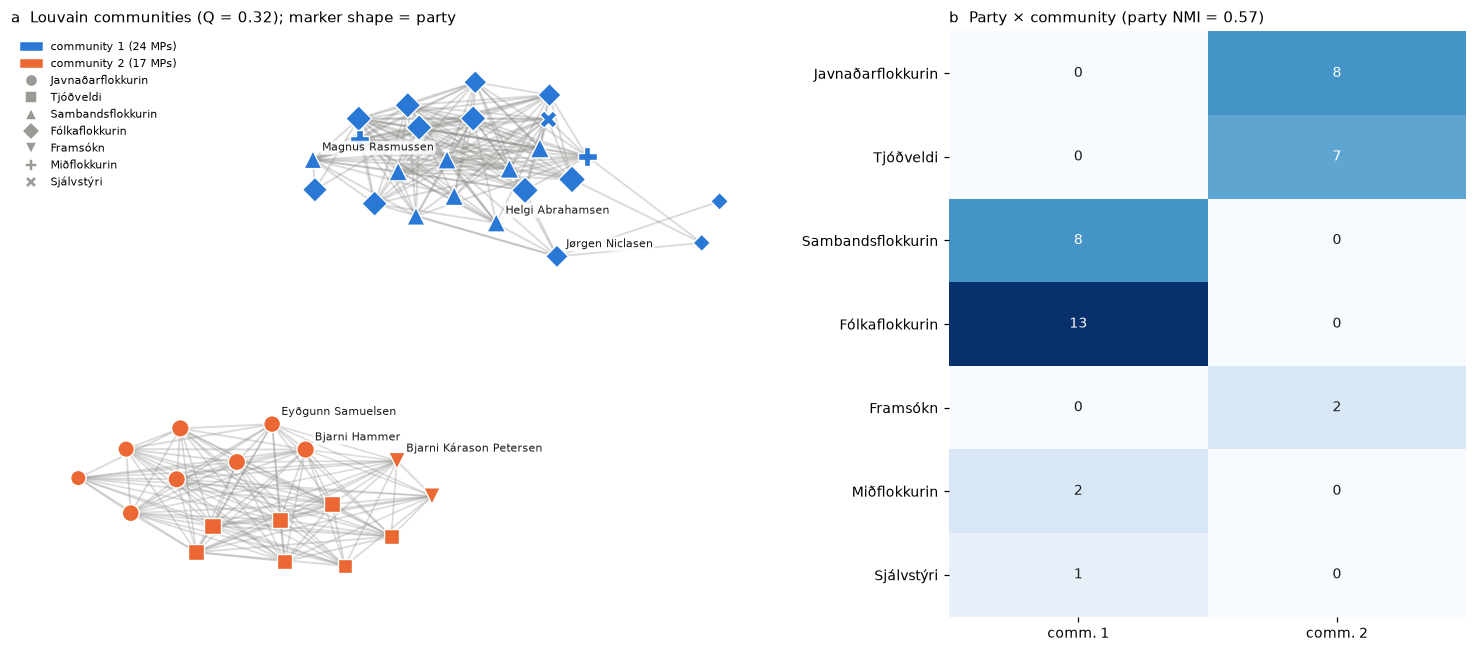

In [23]:
# Figure 5 -- Louvain communities vs party
COMM_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
fig, ax = plt.subplots(1, 2, figsize=(13.5, 6), gridspec_kw={"width_ratios": [1.5, 1]})
draw_network(ax[0], {n: COMM_COLORS[comm_of[n] % len(COMM_COLORS)] for n in Gc},
             f"a  Louvain communities (Q = {louv['modularity_best_of_20']:.2f}); marker shape = party")
ax[0].legend(handles=[Patch(color=COMM_COLORS[k % len(COMM_COLORS)], label=f"community {k + 1} ({len(c)} MPs)")
                      for k, c in enumerate(nonisol_comms)] + party_handles({p: "#9a9994" for p in N.PARTY_ORDER}),
             loc="upper left", fontsize=7)
ct = pd.crosstab(nm[nm.community >= 0].party, nm[nm.community >= 0].community).reindex(
    [p for p in N.PARTY_ORDER if p in set(nm[nm.community >= 0].party)]).fillna(0).astype(int)
im = ax[1].imshow(ct.to_numpy(), cmap="Blues", aspect="auto")
ax[1].set_xticks(range(ct.shape[1])); ax[1].set_xticklabels([f"comm. {c + 1}" for c in ct.columns])
ax[1].set_yticks(range(ct.shape[0])); ax[1].set_yticklabels(ct.index)
for (r_, c_), v_ in np.ndenumerate(ct.to_numpy()):
    ax[1].text(c_, r_, v_, ha="center", va="center", color="white" if v_ > ct.to_numpy().max() / 2 else INK)
ax[1].set_title(f"b  Party × community (party NMI = {louv['party_NMI']:.2f})", loc="left")
ax[1].spines[["left", "bottom"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "fig5_communities_vs_party")
plt.show()

**Figure 5.** (a) The same backbone coloured by Louvain community (best modularity of 20 seeds); marker shape = party. (b) Number of MPs of each party in each community. A party that sits entirely in one community and a community that mixes several parties are both visible here; NMI summarises the overall match.

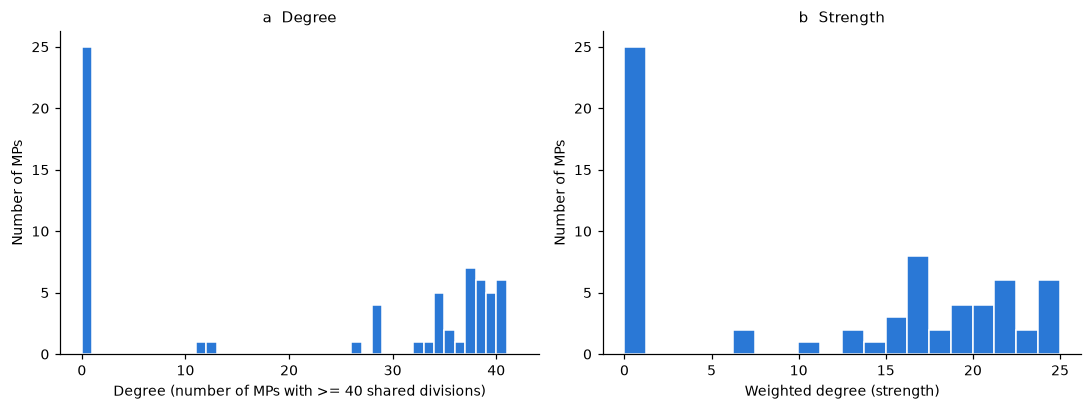

MPs with degree 0 (isolated at this threshold): 25


In [24]:
# supplementary figure -- degree and strength distributions of the thresholded network
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(nm.degree, bins=range(0, int(nm.degree.max()) + 3), color=C_FOR, edgecolor="white")
ax[0].set(xlabel="Degree (number of MPs with >= 40 shared divisions)", ylabel="Number of MPs", title="a  Degree")
ax[1].hist(nm.strength, bins=20, color=C_FOR, edgecolor="white")
ax[1].set(xlabel="Weighted degree (strength)", ylabel="Number of MPs", title="b  Strength")
fig.tight_layout()
save_fig(fig, "figS1_degree_strength")
plt.show()
print("MPs with degree 0 (isolated at this threshold):", int((nm.degree == 0).sum()))

## 9. Export results

All files go to `network_analysis/outputs/`. The pairwise table follows the **shared format** agreed for the project — `mp_id_1`, `mp_id_2`, `similarity`, `n_shared_divisions` come first, with `mp_id_1 < mp_id_2` (each pair once) — followed by diagnostics. **`mp_id` is the only key** (names are for display).

The dissent table is *exploratory*: dissent here means voting against the strict For/Against plurality of one's own party in a division where ≥ 3 party members cast For/Against and the party was not tied (blank and absent are neither). The dedicated dissent workstream may define this differently.

In [25]:
save_table(pairs, "pairwise_voting_similarity.csv")
save_table(nm.round(6), "network_metrics.csv")
save_table(nm[["mp_id", "name", "party", "community"]], "network_communities.csv")
save_table(scenarios.round(6), "sensitivity_scenarios.csv")
save_table(pp_mean.round(4), "party_pair_similarity.csv", index=True)
save_table(top_cross.round(4), "top_cross_party_pairs.csv")

# exploratory dissent x network summary
dis = N.dissent_table(ballots_w)
lo = pd.concat([pm[["mp_id_1", "mp_id_2", "similarity", "same_party"]].rename(columns={"mp_id_1": "mp", "mp_id_2": "other"}),
                pm[["mp_id_2", "mp_id_1", "similarity", "same_party"]].rename(columns={"mp_id_2": "mp", "mp_id_1": "other"})])
agg = lo.groupby(["mp", "same_party"]).similarity.mean().unstack()
dsum = (nm[["mp_id", "name", "party", "degree", "strength", "community"]]
        .merge(dis, left_on="mp_id", right_index=True, how="left")
        .merge(agg.rename(columns={True: "mean_sim_own_party", False: "mean_sim_other_parties"}),
               left_on="mp_id", right_index=True, how="left"))
dsum["own_minus_other_similarity"] = dsum.mean_sim_own_party - dsum.mean_sim_other_parties
save_table(dsum.round(6), "dissent_network_summary.csv")

ok = dsum.dropna(subset=["dissent_rate", "own_minus_other_similarity"]).query("n_party_divisions >= 20")
rho_d, p_d = stats.spearmanr(ok.dissent_rate, ok.own_minus_other_similarity)
print(f"MPs with a dissent rate: {int(dsum.dissent_rate.notna().sum())}; total dissenting ballots in window: {int(dis.n_dissent.sum())}")
print(f"exploratory Spearman(dissent rate, own-party minus other-party similarity) = {rho_d:.3f}, p = {p_d:.3f}, n = {len(ok)} MPs")
display(dsum.sort_values("n_dissent", ascending=False).head(8).round(3))
R["dissent_exploratory"] = {"definition": "vote against the strict For/Against plurality of own party; units with >=3 party voters, no ties",
                            "n_dissenting_ballots": int(dis.n_dissent.sum()), "n_mps_with_rate": int(dsum.dissent_rate.notna().sum()),
                            "spearman_dissent_vs_own_minus_other": {"rho": float(rho_d), "p": float(p_d), "n_mps": int(len(ok)), "exploratory": True}}

MPs with a dissent rate: 57; total dissenting ballots in window: 70
exploratory Spearman(dissent rate, own-party minus other-party similarity) = -0.131, p = 0.446, n = 36 MPs


,mp_id,name,party,degree,strength,community,n_party_divisions,n_dissent,dissent_rate,mean_sim_other_parties,mean_sim_own_party,own_minus_other_similarity
26,MPID000027,Henrik Old,Javnaðarflokkurin,40,19.216,1,613.0,12.0,0.020,0.380,0.952,0.572
18,MPID000019,Johan Dahl,Sambandsflokkurin,39,24.058,0,617.0,9.0,0.015,0.541,0.965,0.424
9,MPID000010,Annika Olsen,Fólkaflokkurin,33,20.025,0,338.0,6.0,0.018,0.513,0.954,0.440
42,MPID000045,Páll á Reynatúgvu,Tjóðveldi,34,13.752,1,395.0,6.0,0.015,0.309,0.961,0.652
40,MPID000043,Beinta Løwe,Tjóðveldi,34,13.342,1,508.0,6.0,0.012,0.293,0.967,0.674
30,MPID000031,Bjarni Hammer,Javnaðarflokkurin,39,19.419,1,474.0,3.0,0.006,0.393,0.977,0.584
2,MPID000003,Jørgen Niclasen,Fólkaflokkurin,26,15.479,0,236.0,3.0,0.013,0.506,0.969,0.463
36,MPID000039,Høgni Hoydal,Tjóðveldi,38,15.177,1,374.0,3.0,0.008,0.291,0.976,0.685


In [26]:
def to_py(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, (pd.Timestamp,)): return str(o.date())
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(type(o))

R["identifiers"] = {"primary_key": "mp_id (string, 'MPID%06d' of the logting.fo actor id; identical to the FPSC mp_id)",
                    "pairwise_table": "network_analysis/outputs/tables/pairwise_voting_similarity.csv",
                    "pairwise_columns_shared_format": ["mp_id_1", "mp_id_2", "similarity", "n_shared_divisions"],
                    "pair_ordering": "mp_id_1 < mp_id_2 (each unordered pair once)"}
R["decisions"] = {
    "valid_votes": "Fyri and Ímóti only; Blankt excluded from numerator and denominator; absent never counted",
    "contested_division": ">= 1 Fyri and >= 1 Ímóti among cast votes",
    "similarity": "matching valid votes / jointly observed contested divisions",
    "main_min_overlap": MAIN_OVERLAP,
    "party_label": "party at which the MP cast most ballots in the window (one MP changed party)",
    "window": "meeting_date in 2020-07-29..2023-05-04; undated divisions excluded",
    "betweenness_distance": "1 / similarity",
    "louvain": "networkx louvain_communities, weight=similarity, resolution 1, best modularity of 20 seeds",
    "backbone": f"disparity filter alpha={BACKBONE_ALPHA}, visualisation only"}
res_path = N.output_path(ROOT, "results", "network_results.json")
res_path.write_text(json.dumps(R, indent=2, default=to_py, ensure_ascii=False), encoding="utf-8")
print("wrote", res_path.relative_to(ROOT))

wrote outputs\networks\results\network_results.json


## 10. Interpretation and limitations

The numbers quoted in the next cell are computed from the objects above (nothing is typed in by hand); the prose around them is a reading of those results and should be re-read if the data or parameters change.

In [27]:
v, wb40, lg, g40 = R["validation"], R["within_between"]["40"], R["louvain_main"], R["graph_main"]
dv = v["within_division_shuffle"]["table"]
sc = scenarios.set_index("scenario")
comm = nm.set_index("mp_id").community
kk = pairs[pairs.meets_min_overlap_40]
cross = kk[kk.mp_id_1.map(comm) != kk.mp_id_2.map(comm)]
R["cross_community"] = {"n_pairs": len(cross), "max_similarity": float(cross.similarity.max()),
                        "n_pairs_ge_0.5": int((cross.similarity >= 0.5).sum())}
party_block = pp_mean.round(2)
display(Markdown(f"""
**Key numbers (main design: contested divisions, For/Against only, min overlap {MAIN_OVERLAP}, speech window).**

* {R['window']['divisions_in_window_with_ballots']} divisions in the window have a per-MP breakdown; **{R['contested']['n_contested']}** are contested. {R['pairs']['n_mps']} MPs give {R['pairs']['n_pairs']:,} pairs; **{g40['n_edges']}** pairs among **{g40['n_nodes'] - g40['n_isolates']}** MPs reach {MAIN_OVERLAP} shared divisions, and **{g40['n_isolates']}** MPs have no such pair.
* Mean similarity: **{wb40['mean_within']:.3f}** within parties ({wb40['n_within']} pairs) vs **{wb40['mean_between']:.3f}** between parties ({wb40['n_between']} pairs); gap **{wb40['gap_within_minus_between']:.3f}**.
* Party-label permutation: null gap {v['party_label_permutation']['null_mean']:.3f} ± {v['party_label_permutation']['null_sd']:.3f} (max {v['party_label_permutation']['null_max']:.3f}), p = {v['party_label_permutation']['p_one_sided']:.4f} with {v['party_label_permutation']['n_perm']:,} permutations.
* Within-division shuffle ({v['within_division_shuffle']['n_perm']:,} permutations): observed Louvain modularity {dv['louvain_Q']['observed']:.3f} vs null {dv['louvain_Q']['null mean']:.3f} ± {dv['louvain_Q']['null sd']:.3f}; observed party NMI {dv['party_NMI']['observed']:.3f} vs null {dv['party_NMI']['null mean']:.3f} ± {dv['party_NMI']['null sd']:.3f}. Smallest attainable p = {1 / (1 + v['within_division_shuffle']['n_perm']):.3f}.
* Louvain: **{lg['n_communities_nonisolated']}** communities (sizes {lg['community_sizes']}), Q = {lg['modularity_best_of_20']:.3f}, run-to-run NMI {lg['mean_pairwise_NMI_between_seeds']:.2f}; NMI with party = **{lg['party_NMI']:.3f}**; modularity of the 7-party partition itself = {lg['modularity_of_party_partition']:.3f}.
* Pairs whose two MPs are in different Louvain communities: {len(cross)}; the highest similarity among them is **{cross.similarity.max():.2f}** ({int((cross.similarity >= 0.5).sum())} pairs reach 0.5).
* Sensitivity: the within-minus-between gap ranges {scenarios.gap_within_minus_between.min():.3f}–{scenarios.gap_within_minus_between.max():.3f} and party NMI {scenarios.party_NMI.min():.3f}–{scenarios.party_NMI.max():.3f} over the {len(scenarios)} scenarios in section 7.
* Exploratory dissent link: Spearman ρ = {R['dissent_exploratory']['spearman_dissent_vs_own_minus_other']['rho']:.2f} (p = {R['dissent_exploratory']['spearman_dissent_vs_own_minus_other']['p']:.2f}, n = {R['dissent_exploratory']['spearman_dissent_vs_own_minus_other']['n_mps']} MPs).
"""))
print("mean similarity between parties (rows/columns = party):")
display(party_block)


**Key numbers (main design: contested divisions, For/Against only, min overlap 40, speech window).**

* 738 divisions in the window have a per-MP breakdown; **333** are contested. 66 MPs give 2,145 pairs; **712** pairs among **41** MPs reach 40 shared divisions, and **25** MPs have no such pair.
* Mean similarity: **0.984** within parties (123 pairs) vs **0.444** between parties (589 pairs); gap **0.541**.
* Party-label permutation: null gap 0.000 ± 0.042 (max 0.252), p = 0.0001 with 10,000 permutations.
* Within-division shuffle (1,000 permutations): observed Louvain modularity 0.322 vs null 0.037 ± 0.002; observed party NMI 0.573 vs null 0.063 ± 0.021. Smallest attainable p = 0.001.
* Louvain: **2** communities (sizes [24, 17]), Q = 0.322, run-to-run NMI 1.00; NMI with party = **0.573**; modularity of the 7-party partition itself = 0.103.
* Pairs whose two MPs are in different Louvain communities: 362; the highest similarity among them is **0.40** (0 pairs reach 0.5).
* Sensitivity: the within-minus-between gap ranges 0.376–0.561 and party NMI 0.358–0.584 over the 9 scenarios in section 7.
* Exploratory dissent link: Spearman ρ = -0.13 (p = 0.45, n = 36 MPs).


mean similarity between parties (rows/columns = party):


party_2,Javnaðarflokkurin,Tjóðveldi,Sambandsflokkurin,Fólkaflokkurin,Framsókn,Miðflokkurin,Sjálvstýri
party_1,,,,,,,
Javnaðarflokkurin,0.98,0.82,0.23,0.20,0.74,0.19,0.19
Tjóðveldi,0.82,0.98,0.07,0.06,0.85,0.05,0.04
Sambandsflokkurin,0.23,0.07,0.99,0.97,0.21,0.97,0.99
Fólkaflokkurin,0.20,0.06,0.97,0.99,0.18,0.98,0.99
Framsókn,0.74,0.85,0.21,0.18,0.98,0.19,0.21
Miðflokkurin,0.19,0.05,0.97,0.98,0.19,1.00,1.00
Sjálvstýri,0.19,0.04,0.99,0.99,0.21,1.00,NaN


### What does the voting network reveal?

* **Voting similarity is strongly bimodal.** Pairs either agree almost always or rarely (Figure 3a): same-party pairs sit at ≈ 0.98, and most cross-party pairs are either ≈ 1 or low. There is almost nothing in between for same-party pairs.
* **It is structured, not random.** Both nulls are decisively rejected: the within-division shuffle (which keeps every division's tally and participants) gives a similarity spread, Louvain modularity and party NMI far below the observed values, and the party-label permutation never produces a gap near the observed one. *Tested claim:* voting similarity carries MP-specific structure and party labels carry information about it.

### Are voting relationships mainly organised by party?

*Partly — more precisely, by blocs of parties.* Same-party MPs are almost interchangeable, but the party-by-party table shows two groups of parties whose members vote together across party lines (high mean similarity), with low similarity between the groups. Louvain recovers exactly two communities, each containing several parties with no party split across them (Figure 5b), and **the 7-party partition has much lower modularity than the two-community partition**, so the party label alone is not the best description of who votes with whom. The party NMI of about 0.57 reflects this: communities align with parties but merge several of them. That the two groups look like a governing coalition versus opposition is an **inference** from the party composition — government membership is not in the data and was not tested.

### Are there meaningful cross-party relationships?

Yes, but they are systematic rather than idiosyncratic: the most similar cross-party pairs (table in section 6) are all between parties of the same group, with similarity at or near 1 over hundreds of shared divisions. We found no strong cross-party agreement *between* the two groups: the highest similarity of any pair split across the two communities is given in the key numbers above, and the between-group means in the table are low. Whether any individual MP sides with the other group on particular topics is not visible in this aggregate; it needs the division- or case-level (dissent) analysis.

### Which MPs appear structurally central, and what does that mean?

* **Strength and degree** are highest for MPs who served longest and voted in the most contested divisions (see `n_contested_divisions_voted` in `network_metrics.csv`): they have the most partners clearing the overlap threshold. This is tenure, not prominence.
* **Betweenness** is low for everyone and is highest for a handful of MPs who sit on the shortest agreement-paths between the two groups. It marks a *position between blocs in this graph*, not influence, leadership or moderation.
* Neither measure was tested against a null, so they are descriptive.

### Limitations

* **Agreement ≠ ideology.** Contested divisions are shaped by party discipline and government/opposition roles; high similarity can mean "same whip" as much as "same views", and the data cannot separate them.
* **Overlap and coverage.** An MP pair is only defined where both voted, so the threshold of 40 shared contested divisions leaves **25 MPs without any edge** (no pair reaches 40), including the whole group of MPs who first appear after the break at the start of 2023 (only 26 contested divisions follow it; see section 3). Results therefore describe mainly the first period. Threshold 20 includes more MPs but changes the community structure (see the sensitivity table), so the community result is *not* robust to that choice and should be reported together with it.
* **Pooled periods.** Similarity pools two periods with different membership; the single party-switching MP is assigned the party under which they cast most ballots.
* **Absence is uninformative here** (illness, substitutes, ministerial duty and boycott look identical), and 11 divisions with only a tally and 7 undated divisions are not usable.
* **Contested divisions only.** The 405 divisions with no Against vote are dropped by design; blank votes are excluded (a third-category treatment correlates 0.99 with the main similarity).
* **Dense graph.** The thresholded graph is nearly complete with a bimodal weight distribution, so the disparity filter (used only for drawing) needed α = 0.2, and modularity mostly picks out the two blocs.

### How should these outputs be compared with the speech-similarity networks?

* **Use the same MPs and pairs.** Join on `mp_id_1`, `mp_id_2` and restrict to pairs that exist in *both* networks (voting: `n_shared_divisions ≥ threshold`; speech: whatever minimum the speech workstream sets). Report how many MPs and pairs survive.
* **Compare full weighted matrices, not communities.** The natural test is a Mantel-type correlation between the voting-similarity and speech-similarity dyads with a permutation null that shuffles MP labels (so dyads sharing an MP stay dependent); Louvain and NMI are supporting evidence only.
* **The voting matrix is bimodal and block-structured**, so a correlation can be driven entirely by the between-bloc contrast. Also report the comparison *within* the two groups of parties, or after controlling for same-party and same-group indicators, otherwise a speech-similarity effect cannot be distinguished from a bloc effect.
* **Keep identifiers stable** (`mp_id`), keep the period split in mind (speech data stops on 2023-05-04, voting similarity is dominated by the first period), and do not read cosine similarity of speech or agreement of votes as political agreement.

In [28]:
# check that the prose numbers hard-wired above still match the computed ones (guards against stale text)
assert g40["n_isolates"] == 25 and R["period_break"]["contested_p2"] == 26, "update the limitations text in section 10"
print("limitations text consistent with computed values")

limitations text consistent with computed values


## Output check

Reads every exported file back from disk and lists it.

In [29]:
out_root = ROOT / "network_analysis" / "outputs"
rows = []
for p in sorted(out_root.rglob("*")):
    if p.is_file():
        info = ""
        if p.suffix == ".csv":
            d = pd.read_csv(p); info = f"{d.shape[0]} rows x {d.shape[1]} cols"
        elif p.suffix == ".json":
            info = f"{len(json.loads(p.read_text(encoding='utf-8')))} top-level keys"
        rows.append({"file": str(p.relative_to(ROOT)).replace("\\", "/"), "size_kB": round(p.stat().st_size / 1024, 1), "content": info})
display(pd.DataFrame(rows))
pw = pd.read_csv(out_root / "tables" / "pairwise_voting_similarity.csv")
assert list(pw.columns[:4]) == ["mp_id_1", "mp_id_2", "similarity", "n_shared_divisions"]
assert (pw.mp_id_1 < pw.mp_id_2).all() and not pw.duplicated(["mp_id_1", "mp_id_2"]).any()
print("shared pairwise format verified:", len(pw), "pairs,", pw.similarity.notna().sum(), "with a defined similarity")

,file,size_kB,content
0,outputs/network_analysis/figures/fig1_bipartite_struct...,38.4,
1,outputs/network_analysis/figures/fig1_bipartite_struct...,173.6,
2,outputs/network_analysis/figures/fig2_voting_similarit...,25.4,
3,outputs/network_analysis/figures/fig2_voting_similarit...,439.7,
4,outputs/network_analysis/figures/fig3_similarity_distr...,38.4,
5,outputs/network_analysis/figures/fig3_similarity_distr...,144.9,
6,outputs/network_analysis/figures/fig4_within_vs_betwee...,33.3,
7,outputs/network_analysis/figures/fig4_within_vs_betwee...,282.0,
8,outputs/network_analysis/figures/fig5_communities_vs_p...,33.5,
9,outputs/network_analysis/figures/fig5_communities_vs_p...,587.4,


shared pairwise format verified: 2145 pairs, 1432 with a defined similarity
